In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn nltk joblib

In [45]:
import sklearn
import nltk
import streamlit

print("scikit-learn:", sklearn.__version__)
print("nltk:", nltk.__version__)
print("streamlit:", streamlit.__version__)

scikit-learn: 1.4.2
nltk: 3.8.1
streamlit: 1.32.0


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import joblib

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
from sklearn.naive_bayes import BernoulliNB,MultinomialNB
from sklearn.metrics import (
      accuracy_score,
      precision_score,
      recall_score,
      f1_score,
      confusion_matrix,
      classification_report
)
      

#### Load the Dataset

In [6]:
df = pd.read_csv("output.csv",sep=None,engine="python")

In [7]:
print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Columns:",df.columns.tolist())

Dataset loaded successfully
Shape: (1000, 2)
Columns: [' Review', 'Liked']


In [8]:
df.head(10)

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1
5,Now I am getting angry and I want my damn pho.,0
6,Honeslty it didn't taste THAT fresh.),0
7,The potatoes were like rubber and you could te...,0
8,The fries were great too.,1
9,A great touch.,1


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0    Review  1000 non-null   object
 1   Liked    1000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 15.8+ KB


In [10]:
df.columns = df.columns.str.strip().str.lower()
print(df.columns.tolist())

['review', 'liked']


#### Explore the dataset

In [11]:
print(df["liked"].value_counts())

liked
1    500
0    500
Name: count, dtype: int64


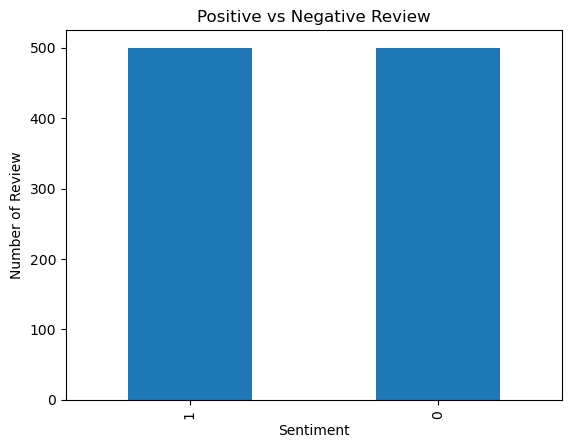

In [12]:
df["liked"].value_counts().plot(
    kind="bar",
    title="Positive vs Negative Review"
)
plt.xlabel("Sentiment")
plt.ylabel("Number of Review")
plt.show()

#### Check missing values

In [13]:
print(df.isnull().sum())

review    0
liked     0
dtype: int64


In [14]:
df = df.dropna(subset=["review","liked"]).copy()
df["review"] = df["review"].astype(str)
print("Shape after removing missing values:", df.shape)

Shape after removing missing values: (1000, 2)


#### Check duplicate reviews

In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 4


In [16]:
df = df.drop_duplicates().copy()

#### Check review text length

In [18]:
df["review_length"] = df["review"].str.len()
print(df["review_length"].describe())

count    996.000000
mean      58.459839
std       32.341292
min       11.000000
25%       33.000000
50%       51.000000
75%       80.000000
max      149.000000
Name: review_length, dtype: float64


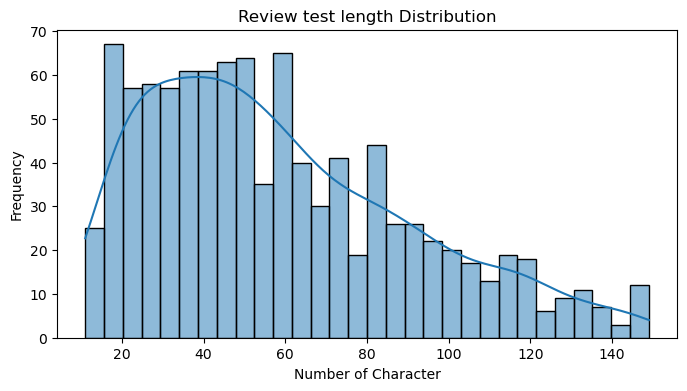

In [19]:
plt.figure(figsize=(8,4))
sns.histplot(df["review_length"], bins=30,kde=True)
plt.title("Review test length Distribution")
plt.xlabel("Number of Character")
plt.ylabel("Frequency")
plt.show()

#### Clean and process the review

In [20]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\BIDYASHREE\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\BIDYASHREE\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\BIDYASHREE\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [21]:
stop_words = set(stopwords.words("english"))

# Keep these words because they are important for sentiment
stop_words = stop_words - {"not", "no", "nor"}

lemmatizer = WordNetLemmatizer()

In [22]:
def clean_text(text):
    # 1. Convert to lowercase
    text = text.lower()

    # 2. Remove numbers
    text = re.sub(r"\d+", "", text)

    # 3. Remove punctuation and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # 4. Remove extra spaces and split into words
    words = text.split()

    # 5. Remove stopwords and lemmatize
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    # 6. Join the words
    return " ".join(words)

In [23]:
sample = "The FOOD was fantastic! I loved it 100%."

print(clean_text(sample))

food fantastic loved


In [24]:
df["cleaned_review"] = df["review"].apply(clean_text)

df[["review", "cleaned_review"]].head(10)

,review,cleaned_review
0,Wow... Loved this place.,wow loved place
1,Crust is not good.,crust not good
2,Not tasty and the texture was just nasty.,not tasty texture nasty
3,Stopped by during the late May bank holiday of...,stopped late may bank holiday rick steve recom...
4,The selection on the menu was great and so wer...,selection menu great price
5,Now I am getting angry and I want my damn pho.,getting angry want damn pho
6,Honeslty it didn't taste THAT fresh.),honeslty taste fresh
7,The potatoes were like rubber and you could te...,potato like rubber could tell made ahead time ...
8,The fries were great too.,fry great
9,A great touch.,great touch


#### Prepare the target column

In [25]:
print(df["liked"].value_counts())
print(df["liked"].unique())

liked
1    499
0    497
Name: count, dtype: int64
[1 0]


In [26]:
label_map = {
    "negative": 0,
    "positive": 1,
    "no": 0,
    "yes": 1,
    "dislike": 0,
    "like": 1
}

if df["liked"].dtype == "object":
    df["liked"] = (
        df["liked"].astype(str).str.strip().str.lower()
        .map(label_map)
    )

    df = df.dropna(subset=["liked"]).copy()

df["liked"] = df["liked"].astype(int)

print(df["liked"].value_counts())

liked
1    499
0    497
Name: count, dtype: int64


#### split the dataset into training and testing sets

In [27]:
x = df["cleaned_review"]
y = df["liked"]

In [28]:
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [29]:
print("Training samples:",len(x_train))
print("Testing samples:", len(x_test))

Training samples: 796
Testing samples: 200


#### Convert text into numerical features

##### Bag of words

In [32]:
bow_vectorizer = CountVectorizer(binary=True)

X_train_bow = bow_vectorizer.fit_transform(x_train)
X_test_bow = bow_vectorizer.transform(x_test)

print("Training matrix:", X_train_bow.shape)
print("Testing matrix:", X_test_bow.shape)

Training matrix: (796, 1565)
Testing matrix: (200, 1565)


##### TF-IDF

In [34]:
tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(x_train)
X_test_tfidf = tfidf_vectorizer.transform(x_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (796, 1565)
Testing matrix: (200, 1565)


#### Train the Naive Bayes models

In [37]:
bnb_model = BernoulliNB()
bnb_model.fit(X_train_bow,y_train)

BernoulliNB()

In [38]:
#make prediction
y_pred_bnb = bnb_model.predict(X_test_bow)
print(y_pred_bnb[:10])

[1 0 1 1 1 1 1 0 0 0]


In [39]:
mnb_model = MultinomialNB()
mnb_model.fit(X_train_tfidf, y_train)
y_pred_mnb = mnb_model.predict(X_test_tfidf)
print("TF-IDF + MultinomialNB training completed!")

TF-IDF + MultinomialNB training completed!


#### Evaluate the model

In [40]:
def evaluate_model(y_true, y_pred, model_name):
    print("\n", "=" * 40)
    print(model_name)
    print("=" * 40)

    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(
        y_true, y_pred, zero_division=0
    ), 4))
    print("Recall   :", round(recall_score(
        y_true, y_pred, zero_division=0
    ), 4))
    print("F1 Score :", round(f1_score(
        y_true, y_pred, zero_division=0
    ), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"]
    )

    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.show()


BernoulliNB + Binary Bag of Words
Accuracy : 0.775
Precision: 0.7477
Recall   : 0.83
F1 Score : 0.7867

Classification Report:
              precision    recall  f1-score   support

    Negative       0.81      0.72      0.76       100
    Positive       0.75      0.83      0.79       100

    accuracy                           0.78       200
   macro avg       0.78      0.77      0.77       200
weighted avg       0.78      0.78      0.77       200



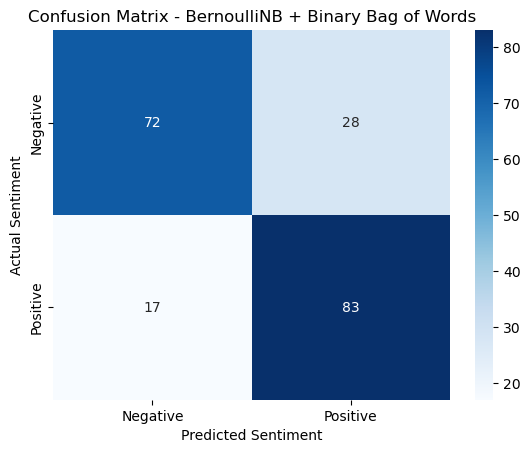

In [41]:
evaluate_model(
    y_test,
    y_pred_bnb,
    "BernoulliNB + Binary Bag of Words"
)


MultinomialNB + TF-IDF
Accuracy : 0.77
Precision: 0.7328
Recall   : 0.85
F1 Score : 0.787

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.69      0.75       100
    Positive       0.73      0.85      0.79       100

    accuracy                           0.77       200
   macro avg       0.78      0.77      0.77       200
weighted avg       0.78      0.77      0.77       200



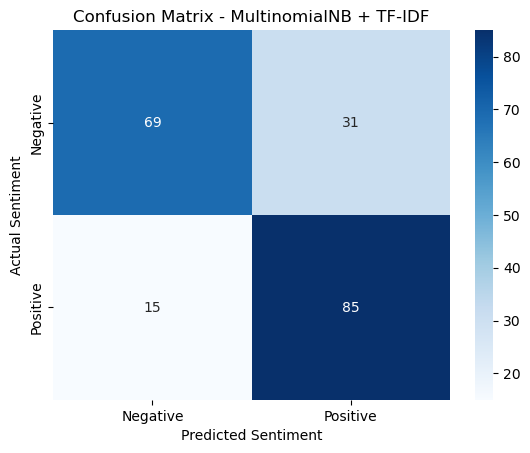

In [42]:
evaluate_model(
    y_test,
    y_pred_mnb,
    "MultinomialNB + TF-IDF"
)

#### Predict the sentiment of new reviews

In [43]:
new_reviews = [
    "The food was fantastic!",
    "Worst service ever."
]

cleaned_new_reviews = [
    clean_text(review) for review in new_reviews
]

new_features = bow_vectorizer.transform(cleaned_new_reviews)

predictions = bnb_model.predict(new_features)
probabilities = bnb_model.predict_proba(new_features)

for review, prediction, probability in zip(
    new_reviews, predictions, probabilities
):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("Confidence:", round(max(probability) * 100, 2), "%")
    print("-" * 40)

Review: The food was fantastic!
Predicted sentiment: Positive
Confidence: 93.78 %
----------------------------------------
Review: Worst service ever.
Predicted sentiment: Negative
Confidence: 86.39 %
----------------------------------------


#### Save your trained model

In [44]:
joblib.dump(
    {
        "model": bnb_model,
        "vectorizer": bow_vectorizer
    },
    "sentiment_model.pkl"
)

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
